In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
df = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\aiml-project\data\processed\cleaned_aqi.csv")
df.head()

,Date,Month,City,AQI_Category,AQI,Pollutant
0,2020-01-01,January,Ahmedabad,Moderate,178,"PM 2.5, PM 10"
1,2020-01-01,January,Panchkula,Moderate,110,"PM 2.5, PM 10"
2,2020-01-01,January,Palwal,Very Poor,385,"PM 2.5, PM 10"
3,2020-01-01,January,Pali,Moderate,154,"PM 2.5, PM 10"
4,2020-01-01,January,Noida,Severe,438,"PM 2.5, PM 10"


In [5]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (378328, 6)

Columns:
['Date', 'Month', 'City', 'AQI_Category', 'AQI', 'Pollutant']


In [7]:
df["Date"] = pd.to_datetime(df["Date"])
print(df["Date"].dtype)

datetime64[ns]


In [9]:
df["Year"] = df["Date"].dt.year
df[["Date", "Year"]].head()

,Date,Year
0,2020-01-01,2020
1,2020-01-01,2020
2,2020-01-01,2020
3,2020-01-01,2020
4,2020-01-01,2020


In [11]:
df["Month_Number"] = df["Date"].dt.month
df[["Date", "Month", "Month_Number"]].head()

,Date,Month,Month_Number
0,2020-01-01,January,1
1,2020-01-01,January,1
2,2020-01-01,January,1
3,2020-01-01,January,1
4,2020-01-01,January,1


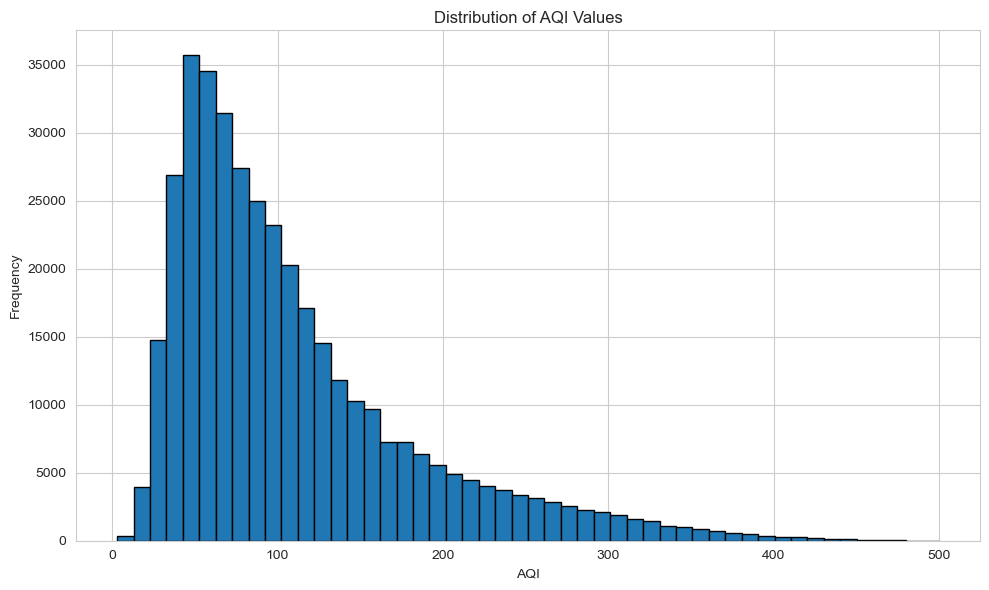

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["AQI"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

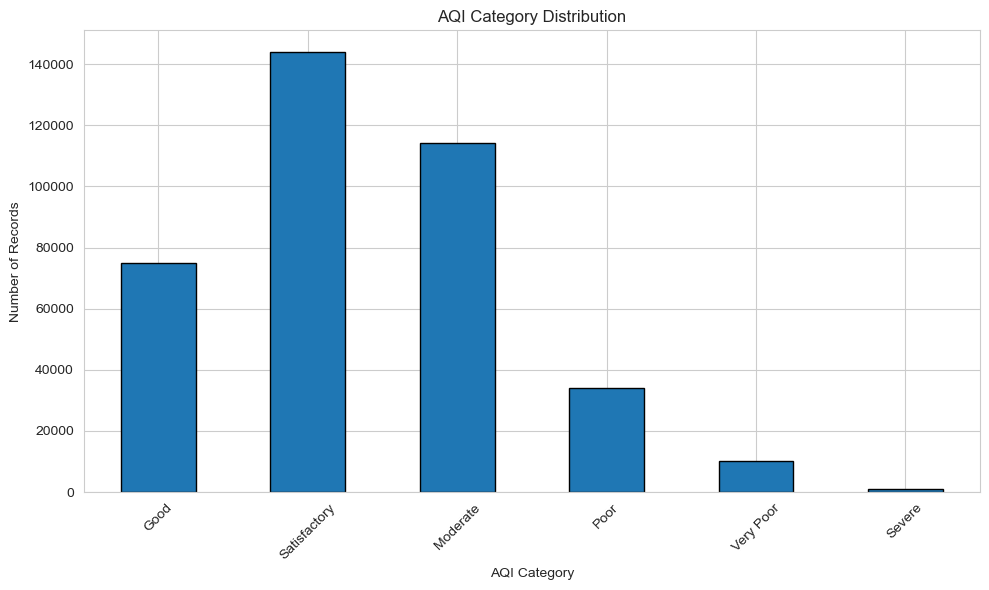

In [13]:
category_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

category_counts = (
    df["AQI_Category"]
    .value_counts()
    .reindex(category_order)
)

plt.figure(figsize=(10, 6))

category_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

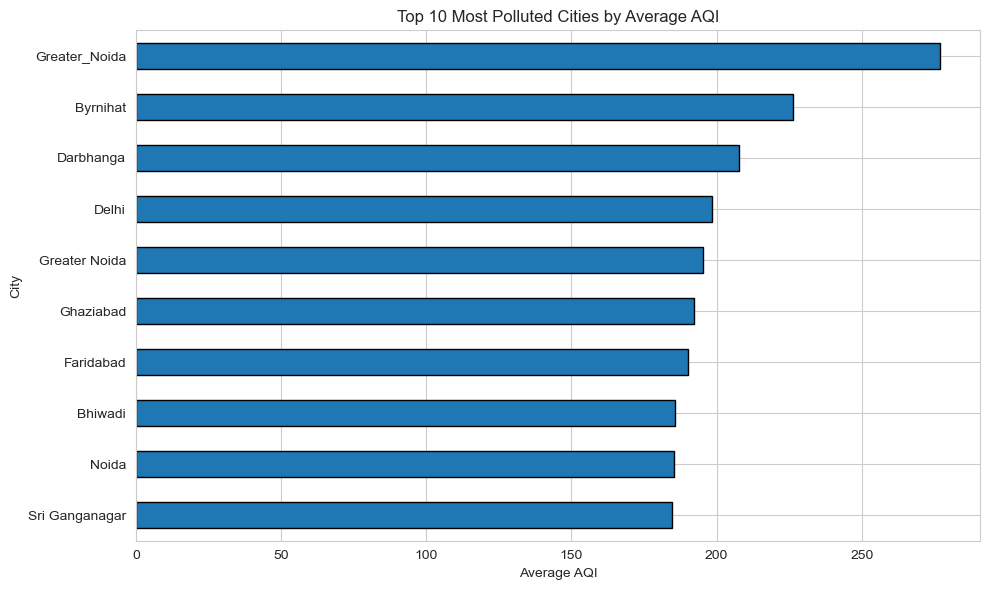

In [14]:
city_avg_aqi = (
    df.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

top_10_polluted = city_avg_aqi.head(10)

plt.figure(figsize=(10, 6))

top_10_polluted.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Most Polluted Cities by Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

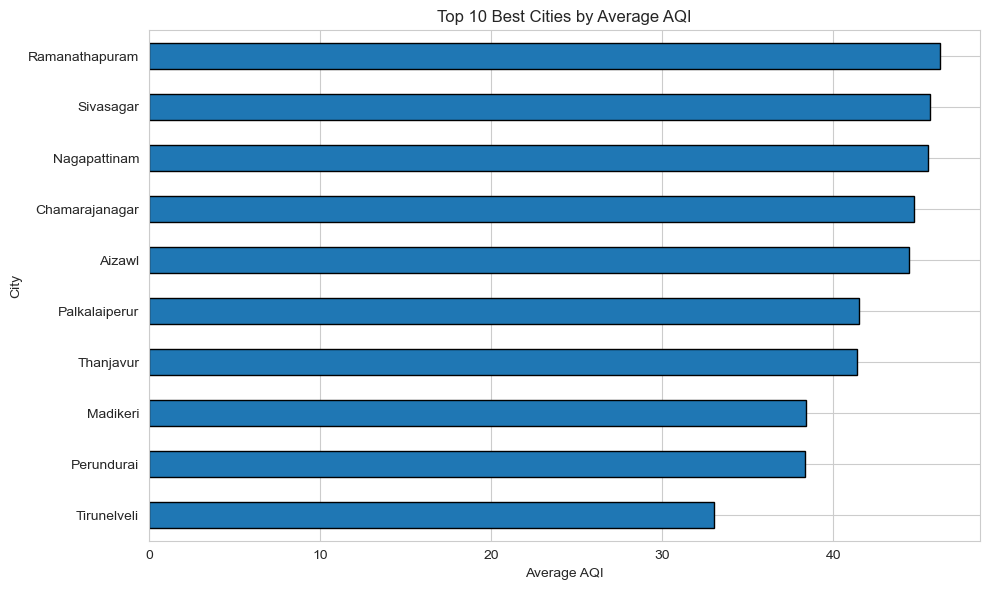

In [15]:
top_10_best = city_avg_aqi.tail(10).sort_values()

plt.figure(figsize=(10, 6))

top_10_best.plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Best Cities by Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

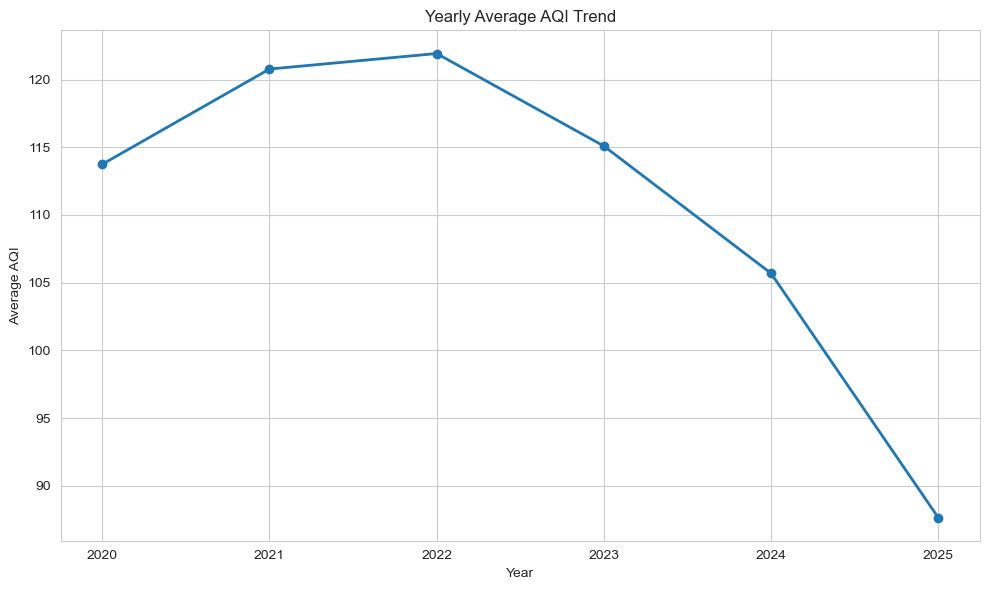

In [16]:
yearly_aqi = (
    df.groupby("Year")["AQI"]
    .mean()
)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly_aqi.index,
    yearly_aqi.values,
    marker="o",
    linewidth=2
)

plt.title("Yearly Average AQI Trend")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.xticks(yearly_aqi.index)

plt.grid(True)

plt.tight_layout()
plt.show()

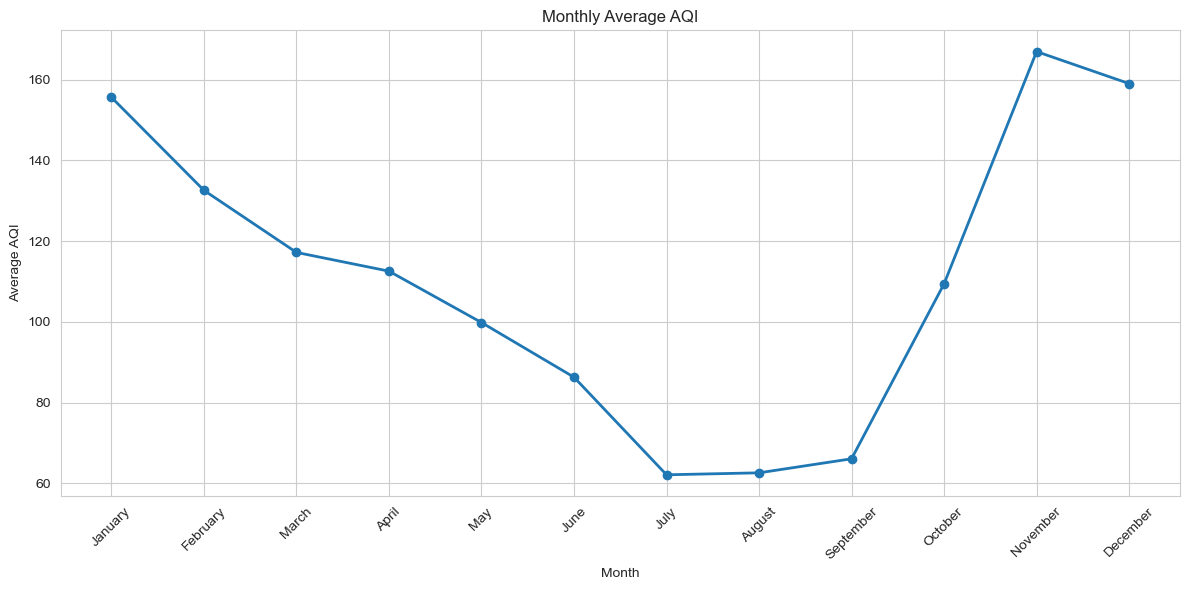

In [17]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_aqi = (
    df.groupby("Month")["AQI"]
    .mean()
    .reindex(month_order)
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_aqi.index,
    monthly_aqi.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()
plt.show()

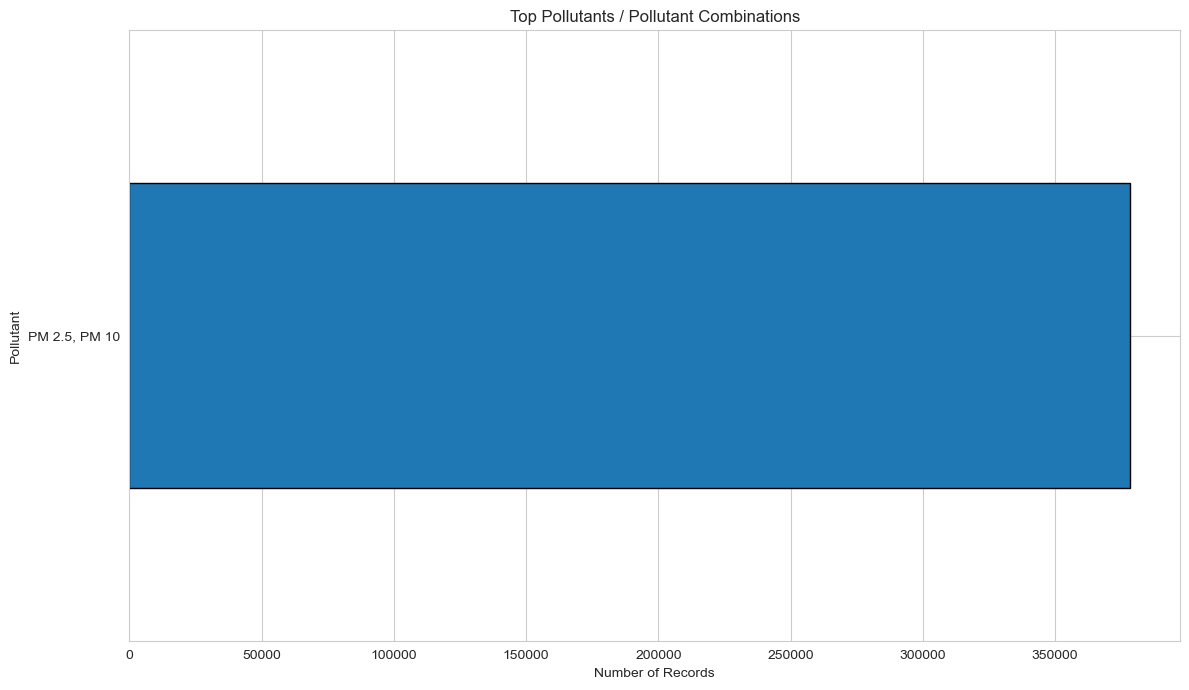

In [18]:
pollutant_counts = (
    df["Pollutant"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))

pollutant_counts.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top Pollutants / Pollutant Combinations")
plt.xlabel("Number of Records")
plt.ylabel("Pollutant")

plt.tight_layout()
plt.show()

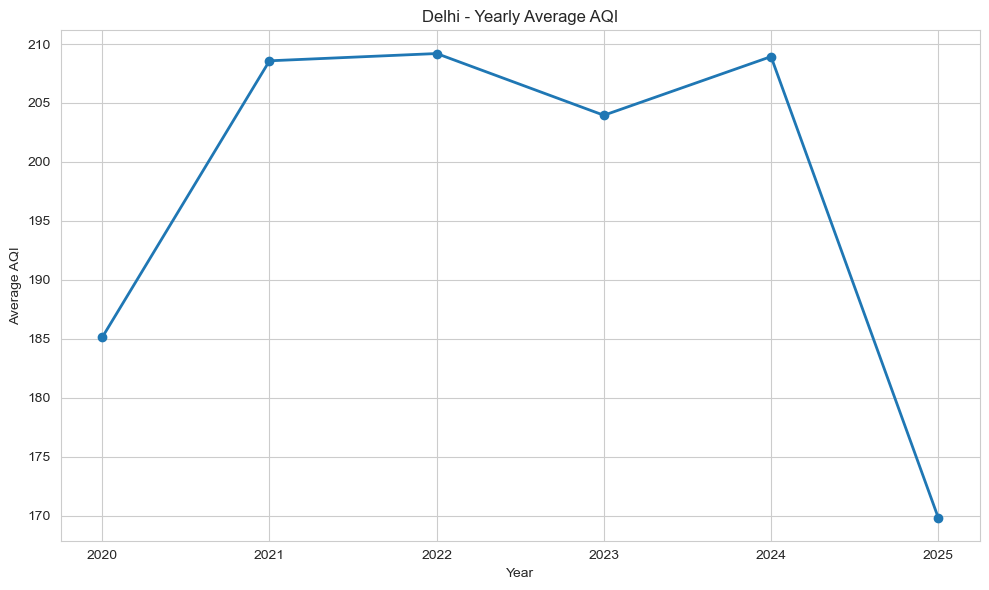

In [19]:
city_name = "Delhi"

city_yearly_aqi = (
    df[df["City"] == city_name]
    .groupby("Year")["AQI"]
    .mean()
)

plt.figure(figsize=(10, 6))

plt.plot(
    city_yearly_aqi.index,
    city_yearly_aqi.values,
    marker="o",
    linewidth=2
)

plt.title(f"{city_name} - Yearly Average AQI")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.xticks(city_yearly_aqi.index)

plt.grid(True)

plt.tight_layout()
plt.show()

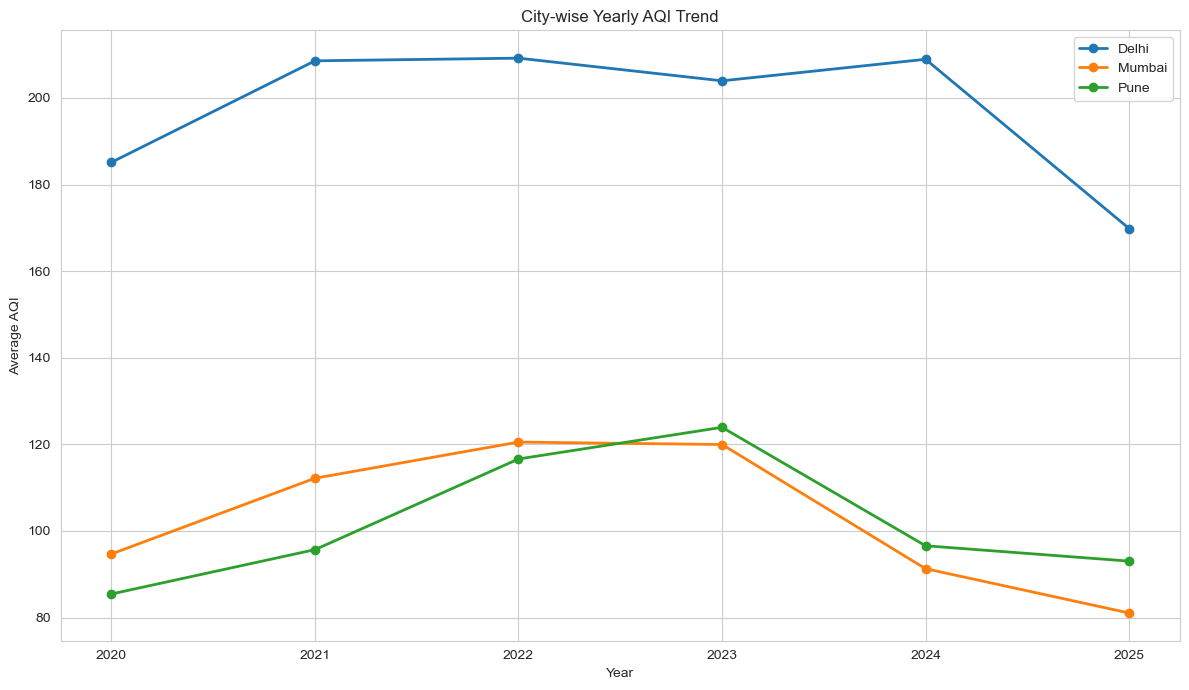

In [20]:
cities = ["Delhi", "Mumbai", "Pune"]

plt.figure(figsize=(12, 7))

for city in cities:

    city_data = (
        df[df["City"] == city]
        .groupby("Year")["AQI"]
        .mean()
    )

    plt.plot(
        city_data.index,
        city_data.values,
        marker="o",
        linewidth=2,
        label=city
    )

plt.title("City-wise Yearly AQI Trend")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

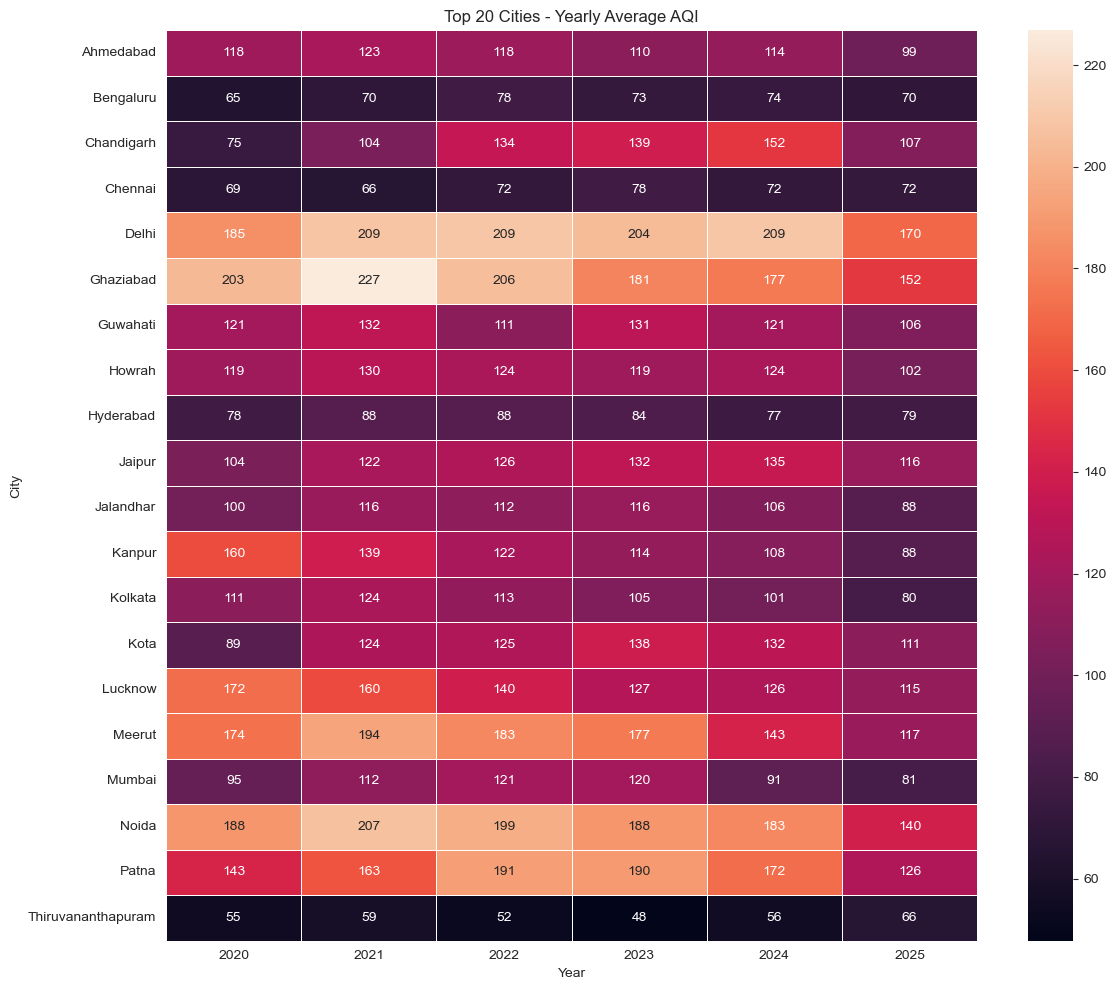

In [24]:
top_cities = (
    df["City"]
    .value_counts()
    .head(20)
    .index
)

city_year_aqi_top = pd.pivot_table(
    df[df["City"].isin(top_cities)],
    values="AQI",
    index="City",
    columns="Year",
    aggfunc="mean"
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    city_year_aqi_top,
    annot=True,
    fmt=".0f",
    linewidths=0.5
)

plt.title("Top 20 Cities - Yearly Average AQI")
plt.xlabel("Year")
plt.ylabel("City")

plt.tight_layout()
plt.show()

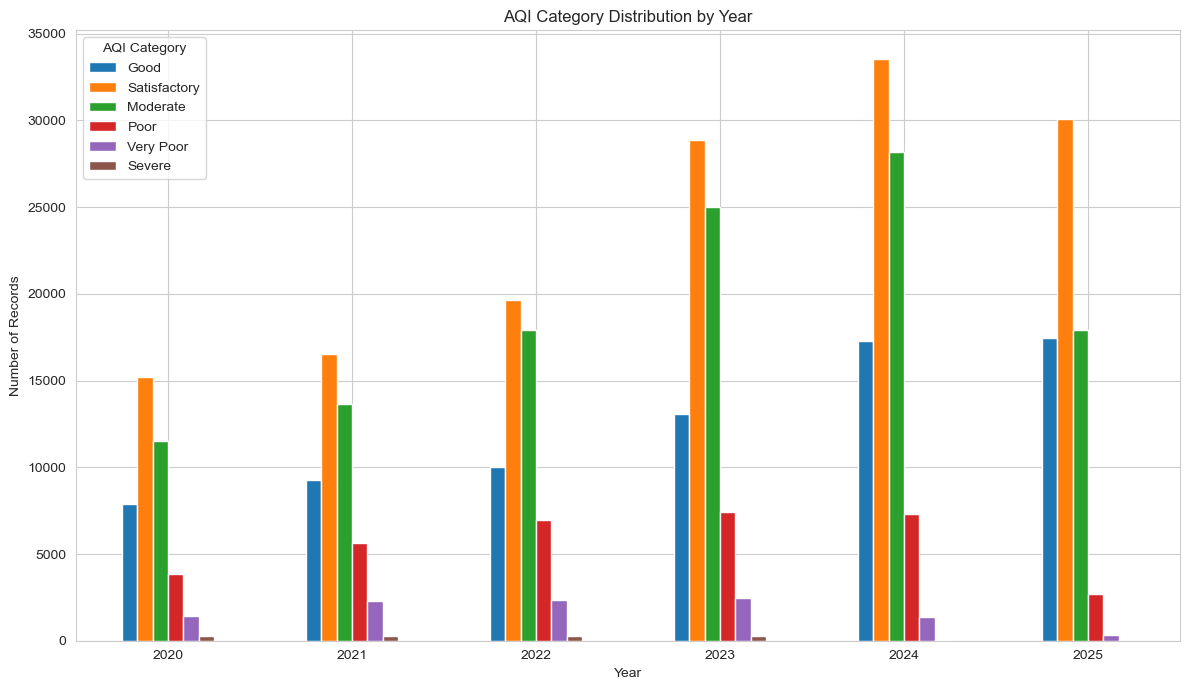

In [25]:
year_category = pd.crosstab(
    df["Year"],
    df["AQI_Category"]
)

year_category

year_category = year_category.reindex(
    columns=category_order,
    fill_value=0
)

year_category

year_category.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("AQI Category Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)
plt.legend(title="AQI Category")

plt.tight_layout()
plt.show()

# EDA Summary

The Exploratory Data Analysis was performed on the cleaned AQI dataset.

### Key analyses performed:

1. **AQI Distribution**
   - Examined the distribution of AQI values.

2. **AQI Category Distribution**
   - Analyzed the number of records in each air quality category.

3. **Top 10 Most Polluted Cities**
   - Identified cities with the highest average AQI.

4. **Top 10 Best Cities**
   - Identified cities with the lowest average AQI.

5. **Yearly AQI Trend**
   - Studied changes in average AQI from 2020 to 2025.

6. **Monthly AQI**
   - Identified monthly patterns in air quality.

7. **Pollutant Distribution**
   - Analyzed the most frequently recorded pollutants.

8. **City-wise AQI Trend**
   - Studied how AQI changed for individual cities over time.

9. **City vs Year Heatmap**
   - Compared average AQI across cities and years.

10. **AQI Category by Year**
    - Analyzed how AQI categories changed over the years.

### Conclusion

The EDA provides a better understanding of air quality patterns across cities, years, months, AQI categories and pollutants.

These findings can be used for further analysis and for developing the AQI prediction Machine Learning model.